# Evaluare 01: Învățarea supervizată
Dataset: *Human Activity Recognition Using Smartphones* (UCI HAR). Fișierele `train.csv` și `test.csv` furnizate sunt concatenate într-un singur set de date (fișierul cerut în enunț).

## 1. Importul datelor

In [ ]:
import pandas as pd
import numpy as np

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
df = pd.concat([train, test], ignore_index=True)
df.to_csv("Human_Activity_Recognition_Using_Smartphones_Data.csv", index=False)

df = pd.read_csv("Human_Activity_Recognition_Using_Smartphones_Data.csv")

# dimensiuni și tipuri de date
print("Dimensiuni:", df.shape)
print(df.dtypes.value_counts())
print("\nColoane non-float:", df.select_dtypes(exclude="float64").columns.tolist())

Dimensiuni: (10299, 563)
float64    561
int64        1
str          1
Name: count, dtype: int64

Coloane non-float: ['subject', 'Activity']


In [15]:
display(df.head())
print("Total valori lipsă:", df.isna().sum().sum())
print("\nDistribuția claselor:")
print(df["Activity"].value_counts())

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


Total valori lipsă: 0

Distribuția claselor:
Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


## 2. Vizualizare date cu Matplotlib și Seaborn

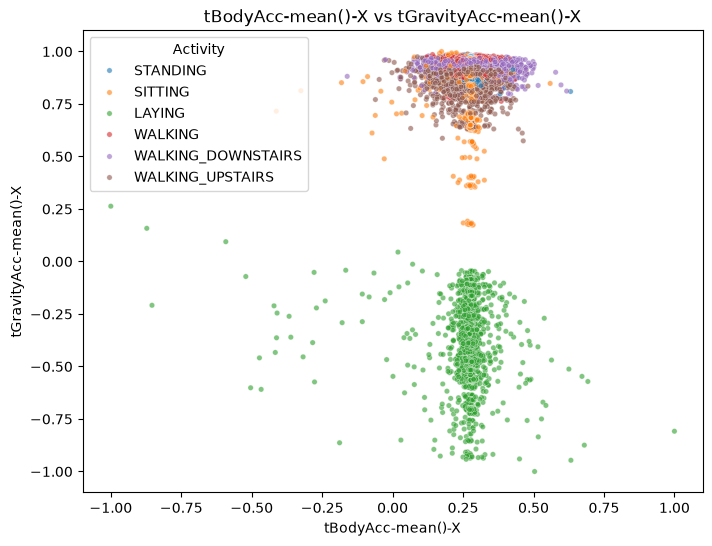

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="tBodyAcc-mean()-X", y="tGravityAcc-mean()-X",
                hue="Activity", alpha=0.6, s=15)
plt.title("tBodyAcc-mean()-X vs tGravityAcc-mean()-X")
plt.show()

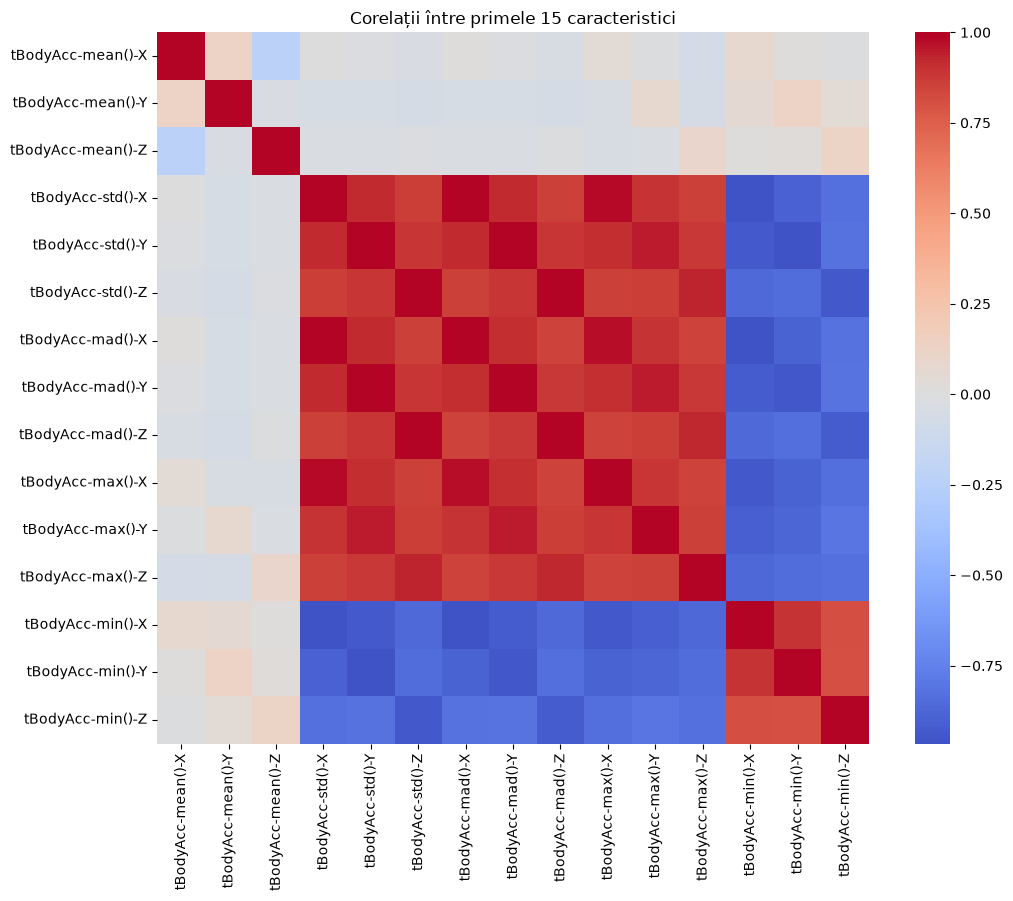

In [ ]:
corr = df.iloc[:, :15].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Corelații între primele 15 caracteristici")
plt.tight_layout()
plt.show()

## 3. Metrici ale erorii
Regresia liniară necesită o țintă numerică: prezicem `tBodyAcc-mean()-X` pe baza celorlalte caracteristici numerice (fără `subject`).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

num = df.drop(columns=["Activity", "subject"])
target = "tBodyAcc-mean()-X"
X_r = num.drop(columns=[target])
y_r = num[target]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_r, y_r, test_size=0.2, random_state=42)

lin = LinearRegression().fit(Xr_train, yr_train)
pred = lin.predict(Xr_test)

mae = mean_absolute_error(yr_test, pred)
mse = mean_squared_error(yr_test, pred)
rmse = np.sqrt(mse)
print(f"MAE : {mae:.6f}")
print(f"MSE : {mse:.6f}")
print(f"RMSE: {rmse:.6f}")

MAE : 0.023176
MSE : 0.001547
RMSE: 0.039331


## 4. Validare încrucișată (Cross Validation)

In [11]:
import sklearn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

print("scikit-learn", sklearn.__version__)

X = df.drop(columns=["Activity", "subject"])
y = df["Activity"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
scores = cross_val_score(knn, X_train, y_train, cv=5, scoring="accuracy")
print("Scoruri pe fold-uri:", np.round(scores, 4))
print(f"Acuratețe medie: {scores.mean():.4f} (+/- {scores.std():.4f})")

scikit-learn 1.9.1
Scoruri pe fold-uri: [0.9684 0.9636 0.966  0.966  0.9654]
Acuratețe medie: 0.9659 (+/- 0.0016)


## 5. Modele de Machine Learning

### 5.1 Regresia liniară (evaluare pe setul de testare)

In [12]:
from sklearn.metrics import r2_score

print(f"R²   (test): {r2_score(yr_test, pred):.4f}")
print(f"RMSE (test): {rmse:.6f}")

R²   (test): 0.6880
RMSE (test): 0.039331


### 5.2 Regresia logistică (clasificare binară)
Transformăm problema în binară: activități **statice** (SITTING, STANDING, LAYING) vs **dinamice** (WALKING*).

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

y_bin = df["Activity"].isin(["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS"]).astype(int)  # 1 = dinamic
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X, y_bin, test_size=0.2, random_state=42, stratify=y_bin)

log_bin = LogisticRegression(max_iter=2000).fit(Xb_train, yb_train)
pb = log_bin.predict(Xb_test)
print("Acuratețe:", round(accuracy_score(yb_test, pb), 4))
print(classification_report(yb_test, pb, target_names=["static", "dinamic"]))

Acuratețe: 1.0
              precision    recall  f1-score   support

      static       1.00      1.00      1.00      1126
     dinamic       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



### 5.3 SVM

In [9]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", C=1.0).fit(X_train, y_train)
ps = svm.predict(X_test)
print("Acuratețe SVM (test):", round(accuracy_score(y_test, ps), 4))
print(classification_report(y_test, ps))

Acuratețe SVM (test): 0.9757
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.93      0.95      0.94       356
          STANDING       0.95      0.93      0.94       381
           WALKING       1.00      1.00      1.00       344
WALKING_DOWNSTAIRS       0.99      0.99      0.99       281
  WALKING_UPSTAIRS       0.99      0.99      0.99       309

          accuracy                           0.98      2060
         macro avg       0.98      0.98      0.98      2060
      weighted avg       0.98      0.98      0.98      2060



## 6. Matricea de confuzie

Acuratețe: 0.9864


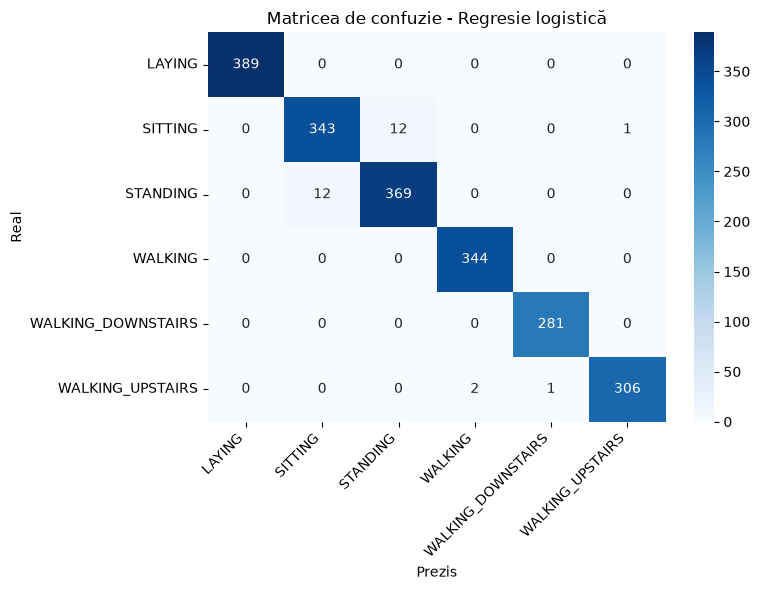

In [14]:
from sklearn.metrics import confusion_matrix

log_clf = LogisticRegression(max_iter=2000).fit(X_train, y_train)
pl = log_clf.predict(X_test)
print("Acuratețe:", round(accuracy_score(y_test, pl), 4))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, pl, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Prezis"); plt.ylabel("Real")
plt.title("Matricea de confuzie - Regresie logistică")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 7. Gradient Descent
Implementare manuală pentru $J(\theta)=\frac{1}{m}\sum(\theta x - y)^2$, pe un subset de 200 de rânduri: $x$ = `tGravityAcc-mean()-X`, $y$ = `tGravityAcc-energy()-X`. Gradientul este $\frac{2}{m}\sum x(\theta x - y)$.

theta final (GD)        : 0.906890
theta analitic (optim)  : 0.906890
cost inițial -> final   : 0.665367 -> 0.094339


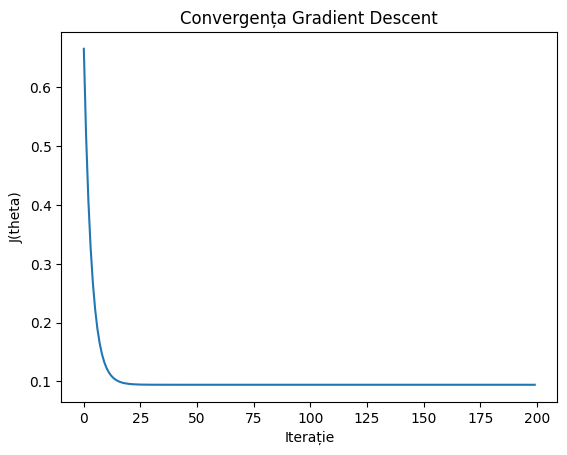

In [11]:
sub = df.sample(200, random_state=42)
x = sub["tGravityAcc-mean()-X"].values
yg = sub["tGravityAcc-energy()-X"].values

def cost(theta):
    return np.mean((theta * x - yg) ** 2)

def grad(theta):
    return 2 * np.mean(x * (theta * x - yg))

theta, lr, n_iter = 0.0, 0.1, 200
history = []
for i in range(n_iter):
    history.append(cost(theta))
    theta -= lr * grad(theta)

print(f"theta final (GD)        : {theta:.6f}")
print(f"theta analitic (optim)  : {np.sum(x*yg)/np.sum(x*x):.6f}")
print(f"cost inițial -> final   : {history[0]:.6f} -> {cost(theta):.6f}")

plt.plot(history)
plt.xlabel("Iterație"); plt.ylabel("J(theta)")
plt.title("Convergența Gradient Descent")
plt.show()

## 8. Modele de Machine Learning (part 2)

### 8.1 Random Forest și importanța caracteristicilor

Acuratețe RF (test): 0.9816


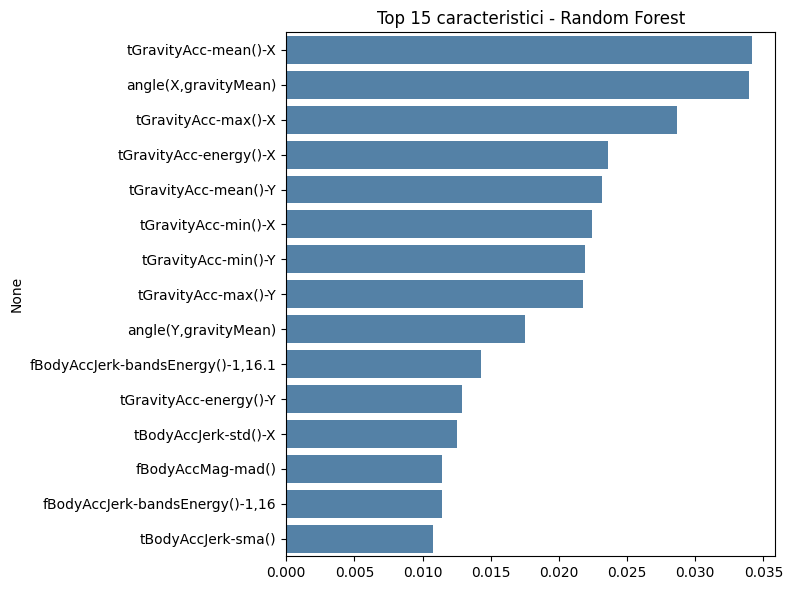

In [12]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)
print("Acuratețe RF (test):", round(accuracy_score(y_test, rf.predict(X_test)), 4))

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=imp.values, y=imp.index, color="steelblue")
plt.title("Top 15 caracteristici - Random Forest")
plt.tight_layout()
plt.show()

### 8.2 AdaBoost vs Bagging

In [13]:
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=30, random_state=42).fit(X_train, y_train)
bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=30, random_state=42, n_jobs=-1).fit(X_train, y_train)

print("AdaBoost:", round(accuracy_score(y_test, ada.predict(X_test)), 4))
print("Bagging :", round(accuracy_score(y_test, bag.predict(X_test)), 4))

AdaBoost: 0.8869
Bagging : 0.967


## 9. Stacking

In [14]:
from sklearn.ensemble import StackingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

base = [
    ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ("svm", SVC(kernel="rbf", probability=True, random_state=42)),
    ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
]
stack = StackingClassifier(estimators=base,
                           final_estimator=LogisticRegression(max_iter=2000),
                           cv=3, n_jobs=-1)
stack.fit(X_train, y_train)
acc = accuracy_score(y_test, stack.predict(X_test))
print(f"Acuratețea finală Stacking (test): {acc:.4f}")

Acuratețea finală Stacking (test): 0.9922
